# **Minneapolis GIS Food Inspections**

# Table of Contents

# Description of Data Set

Your plan should include the following:

1. What will be your goal in working on this project?
2. What will be your source for data for the project? If this requires you to gather data, how will you go about this?
3. What kinds of exploratory data analysis will you do?
4. What data cleaning, conversion, or preparation will you need to do to prepare your data set?
5. Which machine learning algorithms will you use to train models? Why are you choosing these algorithms?
6. How will you attempt to optimize your models?
7. How will you analyze the accuracy of your models?
Your workflow should have some form of data pre-processing, some kind of exploratory data analysis, training and testing of machine learning algorithms (including some parameter tuning), and evaluating the performance of your models. It is very important that your plan is complete and very detailed, in order to show a thorough understanding of the process of training a model using machine learning, in case you don’t have time to fully complete your project.

1. The goal of this project would be to build a model that can predict the heealh inspection scores of the Minneapolis Buisnesses. I will read in the data and use it to train the model to predict a score before the next inspection. The features to particularly put an eye on woul dbe Facility type, risk level, location, inspection type,timing, and the previous inspection's text from the inspector's comments. I plan to do this in the hopes that anyone can use this. Whether it is the health deprtment narrowwing down on what buisnesses need a bit more help and could be inspected those a bit more. This could also be useful to anyone trying to avoid places with poor hygiene to avoid getting sick or anyone trying to uplift or recognize the pros and cons of a business to make sure it gets the care it needs.

3. https://github.com/vargas8-spec/MLproject26 is the source but the dataset is created by Hopkins, M., Reeber, E., Forman, G., & Suermondt, J. (1999). Spambase [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C53G6X. If required to gather data, I would probably reach out to the IT department or look online for another dataset for a specific organizations and see if maybe that looks different. For example, a spam email for a college probably looks much different than a spam email for a mobile phone store like T-Mobile.
3. I would perform both summary statistics and visualizations. More specifically, find the mean, median, standard deviation, and percentiles for all numerical features. Using this, I would see which words are related to spam and create a model that identifies spam emails using those words. Then also see any values that are related to spam. I can create a visualization like a bar chart which lets us see the imbalance between spam and non spam(ham). A box plot will also help us actually see our data.

In [ ]:
!pip install ucimlrepo
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

# fetch dataset
spambase = fetch_ucirepo(id=94)

# data (as pandas dataframes)
X = spambase.data.features
y = spambase.data.targets

In [ ]:
X

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.0,0.000,0.000,0.0,0.778,0.000,0.000,3.756,61,278
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.0,0.000,0.132,0.0,0.372,0.180,0.048,5.114,101,1028
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.0,0.010,0.143,0.0,0.276,0.184,0.010,9.821,485,2259
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.0,0.000,0.137,0.0,0.137,0.000,0.000,3.537,40,191
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.0,0.000,0.135,0.0,0.135,0.000,0.000,3.537,40,191
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4596,0.31,0.00,0.62,0.0,0.00,0.31,0.00,0.00,0.00,0.00,...,0.0,0.000,0.232,0.0,0.000,0.000,0.000,1.142,3,88
4597,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.0,0.000,0.000,0.0,0.353,0.000,0.000,1.555,4,14
4598,0.30,0.00,0.30,0.0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.0,0.102,0.718,0.0,0.000,0.000,0.000,1.404,6,118
4599,0.96,0.00,0.00,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.0,0.000,0.057,0.0,0.000,0.000,0.000,1.147,5,78


In [ ]:
import pandas as pd
import numpy as np

data = np.c_[X,y]
columns = np.append(X.columns, ["target"])
spam_df = pd.DataFrame(data, columns=columns)
spam_df.head(5)

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,target
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61.0,278.0,1.0
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101.0,1028.0,1.0
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485.0,2259.0,1.0
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40.0,191.0,1.0
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40.0,191.0,1.0


In [ ]:
spam_df.describe(include = "all")

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,target
count,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,...,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000
mean,0.104553,0.213015,0.280656,0.065425,0.312223,0.095901,0.114208,0.105295,0.090067,0.239413,...,0.038575,0.139030,0.016976,0.269071,0.075811,0.044238,5.191515,52.172789,283.289285,0.394045
std,0.305358,1.290575,0.504143,1.395151,0.672513,0.273824,0.391441,0.401071,0.278616,0.644755,...,0.243471,0.270355,0.109394,0.815672,0.245882,0.429342,31.729449,194.891310,606.347851,0.488698
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.588000,6.000000,35.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.065000,0.000000,0.000000,0.000000,0.000000,2.276000,15.000000,95.000000,0.000000
75%,0.000000,0.000000,0.420000,0.000000,0.380000,0.000000,0.000000,0.000000,0.000000,0.160000,...,0.000000,0.188000,0.000000,0.315000,0.052000,0.000000,3.706000,43.000000,266.000000,1.000000
max,4.540000,14.280000,5.100000,42.810000,10.000000,5.880000,7.270000,11.110000,5.260000,18.180000,...,4.385000,9.752000,4.081000,32.478000,6.003000,19.829000,1102.500000,9989.000000,15841.000000,1.000000


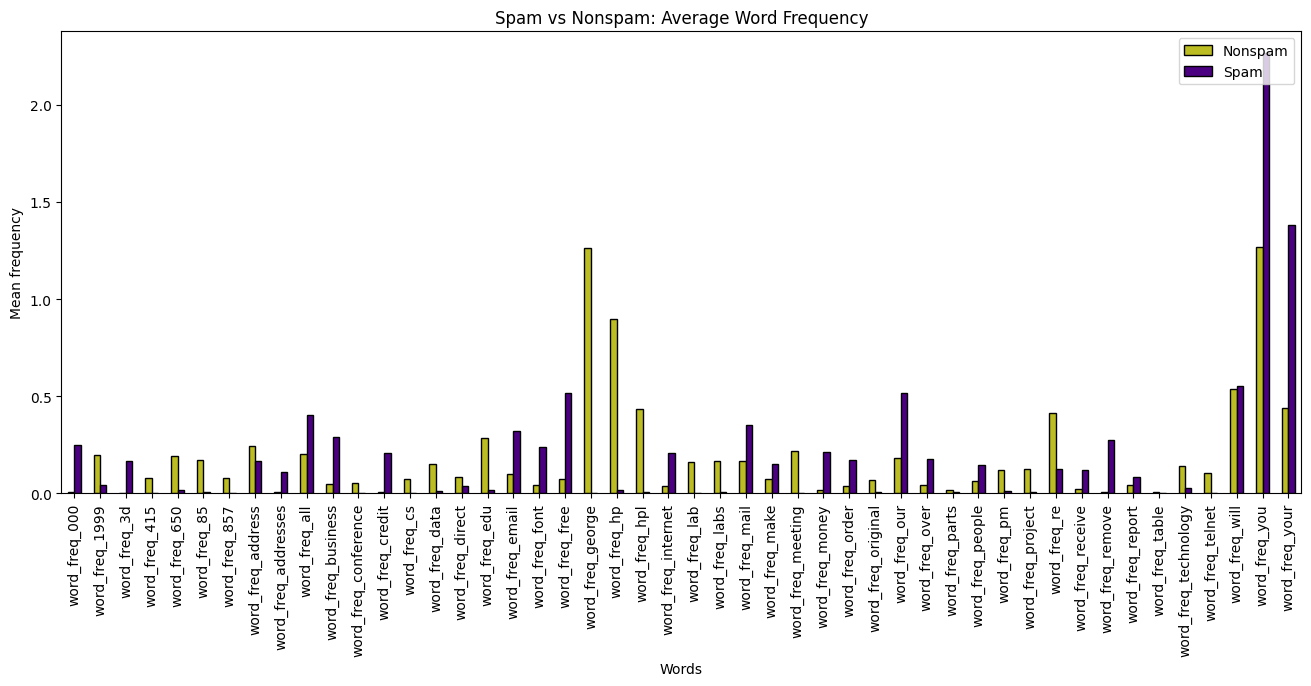

In [ ]:
word_cols = [c for c in spam_df.columns if c.startswith('word_freq_')]

pivot_data = spam_df.pivot_table(columns='target',
                            values=word_cols,
                            aggfunc='mean')

pivot_data.plot(kind='bar', color=['tab:olive', 'indigo'], edgecolor='black',
                figsize=(16, 6))
plt.title('Spam vs Nonspam: Average Word Frequency')
plt.xlabel('Words')
plt.ylabel('Mean frequency')
plt.xticks(rotation=90)
plt.legend(labels=['Nonspam', 'Spam'], loc='upper right')
plt.show()

My dataset: https://archive.ics.uci.edu/dataset/94/spambase (Hopkins, Reeber, Forman, & Suermondt, 1999, doi). Repo: https://github.com/vargas8-spec/MLproject26

Many people have built spam filters using the Spambase dataset, and most get about 92-94% accuracy. Two examples are a comparison of five common models (https://books.aijr.org/index.php/press/catalog/book/114/chapter/1097). I'll use this as my baseline. Some researchers have also tested what happens when a spam filter is trained on one set of emails and tested on a different set (https://arxiv.org/pdf/2504.09776). Another study found that models often get worse on new data, and can learn quirks of the dataset instead of real spam signals (https://www.mdpi.com/2504-2289/10/7/211). The closest project I found uses Spambase and SpamAssassin (https://www.mdpi.com/2079-9292/10/17/2083) and says filters should be adjusted for each organization. As far as I can tell, no one has **tested whether Spambase's built-in bias hurts its results on new data it uses.** Its non-spam emails came from the creators' own inboxes, so words like "george" and the area code 650 point to non-spam (https://farzat.xyz/blog/csca5622-final/notebook.html).

Possible goal: I will build a spam classifier using Spambase and test how well it works on emails from a different source. I'll find which words and features are most connected to spam, then remove "george" and 650 to see how much the model depends on one person's email. Then I'll test it on a second email collection to see if it still works. The goal is a model that could help build an anti-spam filter for an organization. I'll measure precision and recall, because blocking a real email is the costly mistake and I could see this model be used in a real world setting.


**Your task is to see if something similar been done with this type of data. Do a brief write up of background information (one paragraph) making sure to link sources.**

https://books.aijr.org/index.php/press/catalog/book/114/chapter/1097

This article highlights machine learning algorithms and and other methods like Naive Bayes, logistic regression and more to train and evaluate a machine learning model for the detection of spam emails. Similar to what we are doing in class this used the dataset to train and improve a model.

https://arxiv.org/pdf/2504.09776

This investigation features two LLM models and 3 spam datasets. The conclusion was that LLM's are strongly able to catch patterns in textual data to improve spam detection accuracy but that was VERY dependent on having to train on updated and relevant data. "LLM-based spam filters are not immune from an attack strategy that purposefully modifies a message" and "that training with diverse datasets is critical
to their practical deployment." This makes my goal an ambitious one since I could be possibly the first one to try and use other spam databases and see any biases shape out and compare it to the particular one I am doing "spambase".






PC5: Topic modeling, score for bias in all databases, natural language processing, TF/IDF how likely a word appears in a dcoument. Inner frequency a subword

Baseline model: freuwency of spam and nonspam

Decision tree model

Logistic Regression

look for open text dataset. Sms and email data sets.

load in data

Do EDA and feature selection to on  Wednsday